# CNN Image Classification — Facial Expression Recognition (FER-2013)

---

## 1. Project Overview

The goal of this project is to design and compare models for **multi-class facial expression classification** on the **FER-2013 (Facial Expression Recognition)** dataset. The input is a face image; the output is one of **7 emotion classes** (Angry, Disgust, Fear, Happy, Neutral, Sad, Surprise).

Workflow:

- explore the data and document the class distribution and its imbalance,
- explain the evaluation metrics and justify using F1-score on an imbalanced dataset,
- build a preprocessing pipeline with data augmentation designed specifically for faces,
- train a **custom CNN** with hyperparameter tuning via Optuna,
- train a **transfer learning variant** (ResNet18) on RGB 224×224 images,
- compare both approaches, export the models to **ONNX** and build an **inference class** for deployment.


## 2. Imports

In [4]:
# !pip install torch torchvision optuna onnx onnxruntime tensorboard

import os
import time
import json
import shutil
import random
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
import torchvision
import torchvision.transforms as T
from torchvision import models

import optuna
from optuna.trial import Trial
import onnx
import onnxruntime as ort

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="crest")
plt.rcParams["figure.figsize"] = (12, 6)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"CUDA available: {torch.cuda.is_available()}")


d:\School\4_rocnik\HU\Final_project\venv_final\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch version: 2.12.0+cpu
Device: cpu
CUDA available: False


## 3. Exploratory Data Analysis (EDA)

Before building any models, it is important to understand the data thoroughly. For image classification, the key questions are:

- the directory structure and number of images in each split,
- the distribution of emotion classes and the degree of imbalance,
- the visual characteristics of the images (size, contrast, variability).


### 3.1 Loading the Data and Dataset Structure

In [2]:
# FER-2013 — directory structure after extracting the archive:
# archive/
#   train/
#     angry/  disgust/  fear/  happy/  neutral/  sad/  surprise/
#   test/
#     angry/  disgust/  fear/  happy/  neutral/  sad/  surprise/

DATA_ROOT = Path("archive")
TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR  = DATA_ROOT / "test"

assert TRAIN_DIR.exists(), f"Directory {TRAIN_DIR} does not exist — check the dataset location."
assert TEST_DIR.exists(),  f"Directory {TEST_DIR} does not exist — check the dataset location."

# Class names sorted alphabetically (torchvision ImageFolder uses the same order)
CLASSES     = sorted([d.name for d in TRAIN_DIR.iterdir() if d.is_dir()])
NUM_CLASSES = len(CLASSES)
CLASS2IDX   = {cls: idx for idx, cls in enumerate(CLASSES)}
IDX2CLASS   = {idx: cls for cls, idx in CLASS2IDX.items()}

print(f"Number of emotion classes: {NUM_CLASSES}")
print(f"Classes: {CLASSES}")
print(f"Class → index mapping: {CLASS2IDX}")


Number of emotion classes: 7
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Class → index mapping: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}


### 3.2 Image Counts and Class Distribution

In [3]:
def count_images_per_class(split_dir: Path) -> dict:
    """Count the images (PNG/JPG) in each class subdirectory."""
    counts = {}
    for cls in CLASSES:
        cls_path = split_dir / cls
        n = len(list(cls_path.glob("*.png"))) + len(list(cls_path.glob("*.jpg")))
        counts[cls] = n
    return counts

train_counts = count_images_per_class(TRAIN_DIR)
test_counts  = count_images_per_class(TEST_DIR)

stats_df = pd.DataFrame({
    "Class":        CLASSES,
    "Train":        [train_counts[c] for c in CLASSES],
    "Test":         [test_counts[c]  for c in CLASSES],
})
stats_df["Train %"] = (stats_df["Train"] / stats_df["Train"].sum() * 100).round(2)
stats_df["Test %"]  = (stats_df["Test"]  / stats_df["Test"].sum()  * 100).round(2)
stats_df = stats_df.set_index("Class")

print(f"{'='*55}")
print(f"  Total training images: {stats_df['Train'].sum():,}")
print(f"  Total test images:     {stats_df['Test'].sum():,}")
print(f"{'='*55}")
display(stats_df)


  Total training images: 28,709
  Total test images:     7,178


,Train,Test,Train %,Test %
Class,,,,
angry,3995,958,13.92,13.35
disgust,436,111,1.52,1.55
fear,4097,1024,14.27,14.27
happy,7215,1774,25.13,24.71
neutral,4965,1233,17.29,17.18
sad,4830,1247,16.82,17.37
surprise,3171,831,11.05,11.58


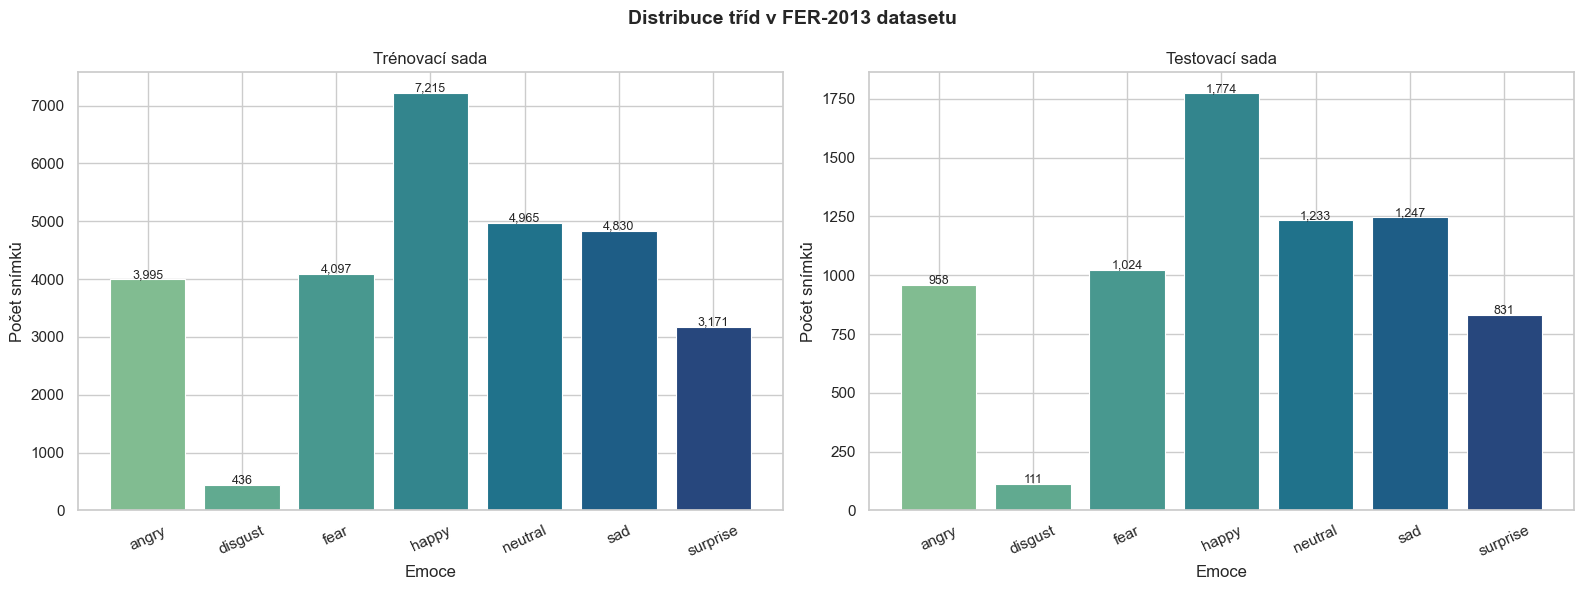

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Class distribution in the FER-2013 dataset", fontsize=14, fontweight="bold")

palette = sns.color_palette("crest", NUM_CLASSES)

# --- Training set ---
bars = axes[0].bar(CLASSES, [train_counts[c] for c in CLASSES], color=palette, edgecolor="white", linewidth=0.8)
axes[0].set_title("Training set", fontsize=12)
axes[0].set_xlabel("Emotion")
axes[0].set_ylabel("Number of images")
axes[0].tick_params(axis="x", rotation=25)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 30, f"{h:,}", ha="center", fontsize=9)

# --- Test set ---
bars2 = axes[1].bar(CLASSES, [test_counts[c] for c in CLASSES], color=palette, edgecolor="white", linewidth=0.8)
axes[1].set_title("Test set", fontsize=12)
axes[1].set_xlabel("Emotion")
axes[1].set_ylabel("Number of images")
axes[1].tick_params(axis="x", rotation=25)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width() / 2, h + 5, f"{h:,}", ha="center", fontsize=9)

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()


### 3.3 Class Imbalance

> **Key observation about dataset imbalance**

FER-2013 suffers from **severe class imbalance**. The *Happy* class dominates the dataset with roughly 7,200 training images, while *Disgust* has only ~440 — a ratio of more than **16:1**.

**Practical consequences:**

- A model trained without correction will systematically favor the majority classes (Happy, Neutral, Sad).
- Overall accuracy can be misleadingly high (the model "learns" the dominant classes) while minority emotions such as Disgust or Fear are ignored.
- False negatives for fear or disgust can be critical in real applications (emotion analysis, assistive technology).

**Mitigations (implemented in this project):**

1. **`class_weight` in the loss function** — inverse class weighting penalizes errors on minority classes more heavily.
2. **`WeightedRandomSampler` in the DataLoader** — oversamples minority classes during training so that each mini-batch is approximately balanced.
3. **Metric choice** — the primary metric is **Macro F1-score**, not accuracy (see Section 4).


### 3.4 Sample Images per Class

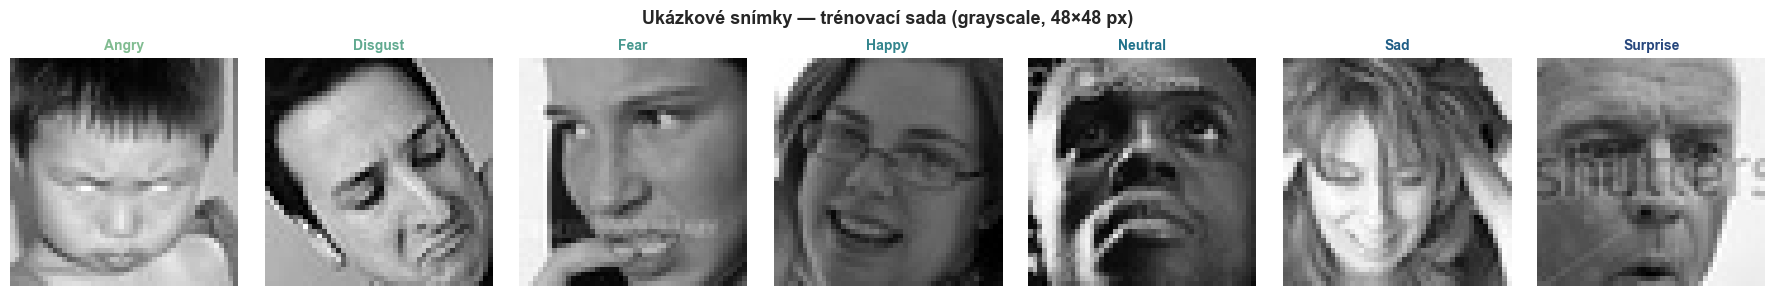

Image resolution: 48×48 px | Channels: 1 (grayscale)


In [5]:
def load_sample_image(class_dir: Path) -> Image.Image:
    """Load the first available image from the given class directory."""
    for ext in ("*.png", "*.jpg"):
        imgs = list(class_dir.glob(ext))
        if imgs:
            return Image.open(imgs[0]).convert("L")  # FER-2013 is grayscale
    raise FileNotFoundError(f"No images found in {class_dir}")

fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(18, 3))
fig.suptitle("Sample images — training set (grayscale, 48×48 px)", fontsize=13, fontweight="bold")

palette_hex = [sns.color_palette("crest", NUM_CLASSES)[i] for i in range(NUM_CLASSES)]

for ax, cls, color in zip(axes, CLASSES, palette_hex):
    img = load_sample_image(TRAIN_DIR / cls)
    ax.imshow(img, cmap="gray")
    ax.axis("off")
    ax.set_title(cls.capitalize(), color=color, fontweight="bold", fontsize=10)

plt.tight_layout()
plt.savefig("sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Image resolution: {img.size[0]}×{img.size[1]} px | Channels: 1 (grayscale)")


## 4. Evaluation Metrics

### 4.1 Why Macro F1-score Matters More Than Accuracy

The classes in this dataset are **heavily imbalanced** — *Happy* makes up about 25% of the training data, while *Disgust* is under 2%. A model that always predicted *Happy* or *Neutral* could reach a respectable accuracy (35–40%), yet it would be practically useless for recognizing the less frequent emotions.

The evaluation therefore focuses on:

- **Macro F1-score** — averages F1 over all classes with **equal weight**, regardless of class frequency. If the model fails on *Disgust*, Macro F1 exposes it immediately.
- **Weighted F1-score** — a complementary metric that reflects the real class distribution and describes the model's overall practical behavior.
- **Per-class recall** — to identify specific classes where the model systematically fails.

Accuracy is still reported, but only as a secondary indicator — **never** as the main criterion for selecting the best model.


In [6]:
def compute_metrics(y_true: list, y_pred: list, label: str = "Model") -> dict:
    """
    Compute a set of classification metrics and print a readable report.
    Returns a dictionary of values for later comparison.
    """
    acc        = accuracy_score(y_true, y_pred)
    f1_macro   = f1_score(y_true, y_pred, average="macro",    zero_division=0)
    f1_weighted= f1_score(y_true, y_pred, average="weighted", zero_division=0)
    prec_macro = precision_score(y_true, y_pred, average="macro",    zero_division=0)
    rec_macro  = recall_score(y_true, y_pred,    average="macro",    zero_division=0)

    print(f"\n{'='*52}")
    print(f"  {label}")
    print(f"{'='*52}")
    print(f"  Accuracy:             {acc:.4f}")
    print(f"  Macro Precision:      {prec_macro:.4f}")
    print(f"  Macro Recall:         {rec_macro:.4f}")
    print(f"  Macro F1-score:       {f1_macro:.4f}  ⭐ (primary metric)")
    print(f"  Weighted F1-score:    {f1_weighted:.4f}")
    print(f"{'='*52}\n")
    print(classification_report(y_true, y_pred, target_names=CLASSES, zero_division=0))

    return {
        "model":        label,
        "accuracy":     round(acc, 4),
        "prec_macro":   round(prec_macro, 4),
        "rec_macro":    round(rec_macro, 4),
        "f1_macro":     round(f1_macro, 4),
        "f1_weighted":  round(f1_weighted, 4),
        "y_pred":       y_pred,
    }


## 5. Preprocessing & Data Augmentation

### 5.1 Choice of Augmentations and Rationale

FER-2013 contains 48×48 px grayscale face images. For compatibility with pretrained models (transfer learning), the images must be:

1. **Upscaled** to 224×224 px (the standard input size for ResNet, EfficientNet, etc.).
2. **Converted from 1 channel to 3 channels** (the grayscale value replicated into each RGB channel) to fit the first convolutional layers of pretrained models.

#### Augmentations used (and why):

| Augmentation | Rationale |
|---|---|
| `RandomHorizontalFlip` | Faces are left-right symmetric — a horizontal flip is completely natural and preserves the expression. |
| `RandomRotation(±15°)` | Mild rotation simulates head tilt. Large rotations (>30°) would be unrealistic and could distort facial geometry. |
| `RandomAffine(translate=0.1)` | A small shift simulates different face positions in the frame. A range of 10% of the side length keeps the face in frame. |
| `ColorJitter(brightness, contrast)` | Simulates lighting variability — different light sources, shadows, overexposure. Key for robustness in real-world deployment. |

#### Excluded augmentations (and why):

| Augmentation | Reason for exclusion |
|---|---|
| `RandomVerticalFlip` | An upside-down face is an extremely rare case that the model will never see in real use. This augmentation would confuse the model rather than strengthen it. |
| `RandomErasing` / `Cutout` | Large cut-outs (>20% of the area) can hide key facial regions — the eyes, the corners of the mouth — without which the emotion is unrecognizable. |
| Extreme `GridDistortion` | Geometric grid distortions would break natural facial proportions and create unrealistic input patterns. |


### 5.2 Preprocessing Pipeline

In [7]:
IMG_SIZE     = 224   # target resolution for transfer learning models
CUSTOM_SIZE  = 48    # resolution for the custom CNN (native FER-2013)

# --- Transforms for the CUSTOM CNN (48×48, 1 channel) ---
custom_train_transform = T.Compose([
    T.Grayscale(num_output_channels=1),
    T.Resize((CUSTOM_SIZE, CUSTOM_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15),
    T.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.ToTensor(),
    T.Normalize(mean=[0.5], std=[0.5]),  # single-channel normalization
])

custom_val_transform = T.Compose([
    T.Grayscale(num_output_channels=1),
    T.Resize((CUSTOM_SIZE, CUSTOM_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.5], std=[0.5]),
])

# --- Transforms for TRANSFER LEARNING (224×224, 3 channels, ImageNet stats) ---
tl_train_transform = T.Compose([
    T.Grayscale(num_output_channels=3),   # grayscale → "RGB" (3 identical channels)
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomRotation(degrees=15),
    T.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),  # ImageNet stats
])

tl_val_transform = T.Compose([
    T.Grayscale(num_output_channels=3),
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

print(" Transforms ready.")
print(f"  Custom CNN input:        {CUSTOM_SIZE}×{CUSTOM_SIZE} px, 1 channel (grayscale)")
print(f"  Transfer learning input: {IMG_SIZE}×{IMG_SIZE} px, 3 channels (ImageNet RGB)")


 Transforms ready.
  Custom CNN input:        48×48 px, 1 channel (grayscale)
  Transfer learning input: 224×224 px, 3 channels (ImageNet RGB)


### 5.3 Dataset and DataLoader

This defines the data the model receives during training.

In [8]:
def build_datasets(train_transform, val_transform):
    """
    Build ImageFolder datasets for the train and test splits.
    The training set is split 80/20 into train/validation.
    """
    full_train = torchvision.datasets.ImageFolder(root=str(TRAIN_DIR), transform=train_transform)
    test_ds    = torchvision.datasets.ImageFolder(root=str(TEST_DIR),  transform=val_transform)

    # 80/20 split of the training set into train + validation
    n_train = int(0.8 * len(full_train))
    n_val   = len(full_train) - n_train
    train_ds, val_ds = torch.utils.data.random_split(
        full_train,
        [n_train, n_val],
        generator=torch.Generator().manual_seed(SEED),
    )
    # The validation set must not use the training augmentations
    val_ds.dataset = torchvision.datasets.ImageFolder(root=str(TRAIN_DIR), transform=val_transform)

    return train_ds, val_ds, test_ds


def build_weighted_sampler(dataset):
    """
    Build a WeightedRandomSampler that oversamples minority classes.
    Every class has the same probability of being drawn into a mini-batch.
    """
    targets = [dataset.dataset.targets[i] for i in dataset.indices]
    class_counts = Counter(targets)
    weights = [1.0 / class_counts[t] for t in targets]
    sampler = WeightedRandomSampler(weights, num_samples=len(weights), replacement=True)
    return sampler


def build_dataloaders(train_ds, val_ds, test_ds, batch_size: int = 64):
    """Build the DataLoaders, using a WeightedRandomSampler for the training set."""
    sampler = build_weighted_sampler(train_ds)
    train_loader = DataLoader(train_ds, batch_size=batch_size, sampler=sampler,
                              num_workers=2, pin_memory=True)
    val_loader   = DataLoader(val_ds,   batch_size=batch_size, shuffle=False,
                              num_workers=2, pin_memory=True)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False,
                              num_workers=2, pin_memory=True)
    return train_loader, val_loader, test_loader


# Initialize the datasets for the custom CNN
custom_train_ds, custom_val_ds, custom_test_ds = build_datasets(
    custom_train_transform, custom_val_transform
)
custom_train_loader, custom_val_loader, custom_test_loader = build_dataloaders(
    custom_train_ds, custom_val_ds, custom_test_ds, batch_size=64
)

print("Dataset overview (Custom CNN — 48×48):")
print(f"  Train:      {len(custom_train_ds):,} images")
print(f"  Validation: {len(custom_val_ds):,} images")
print(f"  Test:       {len(custom_test_ds):,} images")


Dataset overview (Custom CNN — 48×48):
  Train:      22,967 images
  Validation: 5,742 images
  Test:       7,178 images


Class weights make misclassifying minority classes more costly in the loss.

In [9]:
# Compute class weights for the loss function (addresses class imbalance)
all_targets   = custom_train_ds.dataset.targets
train_targets = [all_targets[i] for i in custom_train_ds.indices]

classes_arr   = np.array(sorted(set(train_targets)))
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_arr,
    y=train_targets,
)
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

print("Class weights for the loss function:")
for cls, w in zip(CLASSES, class_weights):
    print(f"  {cls:<10} → {w:.4f}")


Class weights for the loss function:
  angry      → 1.0263
  disgust    → 9.1905
  fear       → 1.0098
  happy      → 0.5680
  neutral    → 0.8315
  sad        → 0.8465
  surprise   → 1.2786


### 5.4 Augmented Batch Preview

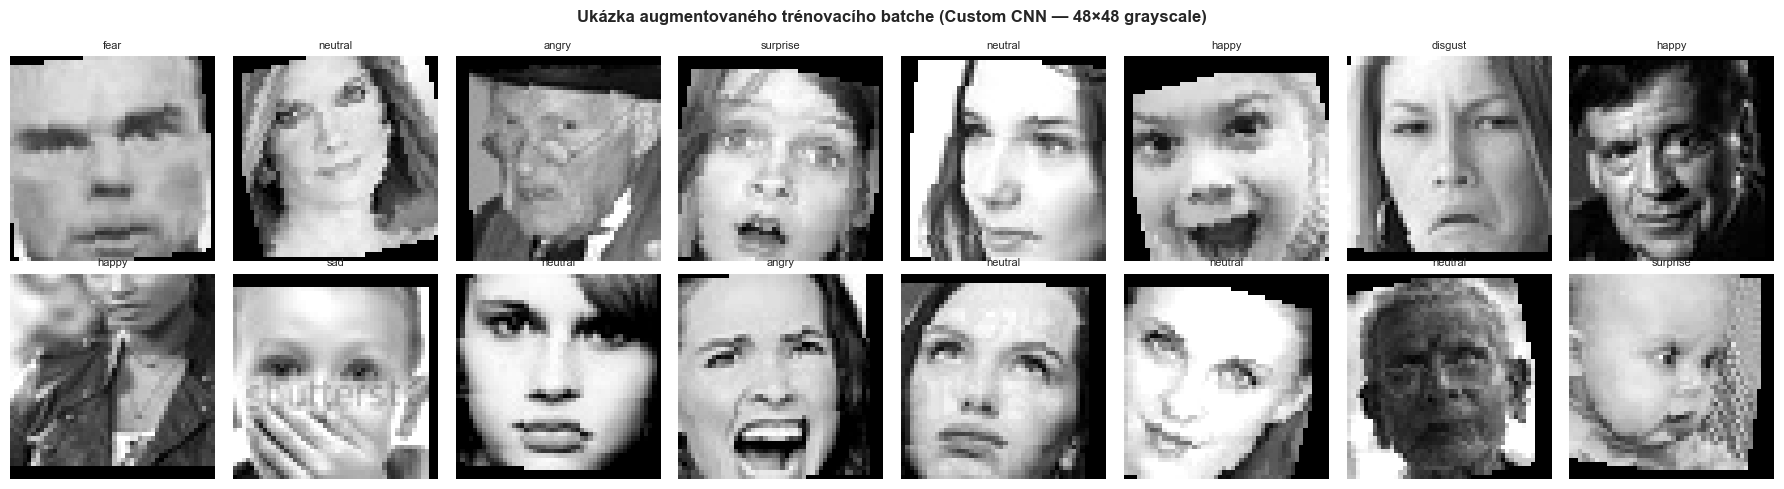

In [10]:
# Visualize one augmented batch — sanity check that the pipeline works correctly
imgs, labels = next(iter(custom_train_loader))

fig, axes = plt.subplots(2, 8, figsize=(18, 5))
fig.suptitle("Augmented training batch (Custom CNN — 48×48 grayscale)",
             fontsize=12, fontweight="bold")

for i, ax in enumerate(axes.flat):
    if i >= len(imgs):
        ax.axis("off")
        continue
    # Denormalize for display
    img = imgs[i].squeeze().numpy()
    img = img * 0.5 + 0.5  # denormalize from [-1,1] → [0,1]
    ax.imshow(img, cmap="gray")
    ax.set_title(IDX2CLASS[labels[i].item()], fontsize=8)
    ax.axis("off")

plt.tight_layout()
plt.savefig("augmented_batch.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Model Development

This section builds two model branches:

- **Custom CNN** — a custom convolutional architecture trained from scratch on 48×48 grayscale images. Hyperparameters are tuned with **Optuna**.
- **Transfer Learning (ResNet18)** — an ImageNet-pretrained model fine-tuned on FER-2013 images upscaled to RGB 224×224.


### 6.1 Training Utilities


#### 6.1.1 Training and Evaluation Loop

In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    """Run one training epoch and return the mean loss and accuracy."""
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total   += imgs.size(0)

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    """Evaluate the model on the given loader — returns loss, accuracy, y_true, y_pred."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []

    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        outputs = model(imgs)
        loss = criterion(outputs, labels)

        total_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total   += imgs.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    return total_loss / total, correct / total, all_labels, all_preds


def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler,
                device, epochs: int):
    """
    Main training loop with best-checkpoint selection by validation Macro F1.
    Returns the training history and the best weights found.
    """
    best_f1, best_weights = 0.0, None
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1_macro": []}

    for epoch in range(1, epochs + 1):
        t_loss, t_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        v_loss, v_acc, y_true, y_pred = evaluate(model, val_loader, criterion, device)
        val_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

        if scheduler is not None:
            scheduler.step(val_f1)

        # Keep the best checkpoint
        if val_f1 > best_f1:
            best_f1 = val_f1
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}

        # Record the epoch in the history
        for key, val in zip(
            ["train_loss", "val_loss", "train_acc", "val_acc", "val_f1_macro"],
            [t_loss, v_loss, t_acc, v_acc, val_f1],
        ):
            history[key].append(val)

        print(f"  Ep {epoch:02d}/{epochs} | "
              f"Train loss: {t_loss:.4f} acc: {t_acc:.4f} | "
              f"Val loss: {v_loss:.4f} acc: {v_acc:.4f} | "
              f"Val Macro F1: {val_f1:.4f}" +
              (" ← best" if val_f1 == best_f1 else ""))

    return history, best_weights


def plot_history(history: dict, title: str):
    """Plot the training history (loss, accuracy and validation Macro F1)."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(title, fontsize=13, fontweight="bold")

    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"],   label="Val")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    axes[1].plot(history["train_acc"], label="Train")
    axes[1].plot(history["val_acc"],   label="Val")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    axes[2].plot(history["val_f1_macro"], color="coral", label="Val Macro F1")
    axes[2].set_title("Validation Macro F1-score")
    axes[2].set_xlabel("Epoch")
    axes[2].legend()
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"history_{title.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()


def show_confusion_matrix(y_true, y_pred, title: str):
    """Plot the confusion matrix for the given model."""
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(10, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASSES)
    disp.plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=30)
    ax.set_title(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.savefig(f"cm_{title.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()


### 6.2 Custom CNN — Architecture and Hyperparameter Tuning (Optuna)

The first model is a convolutional network designed from scratch. The architecture uses progressively wider convolutional blocks with batch normalization, and global average pooling instead of a flatten-and-dense head.

The hyperparameters (number of filters, learning rate, dropout, batch size) are tuned systematically with **Optuna**.


In [13]:
class CustomCNN(nn.Module):
    """
    Custom CNN for emotion classification on 48×48 grayscale images.

    Architecture:
      3× ConvBlock (Conv → BN → ReLU → Conv → BN → ReLU → MaxPool → Dropout)
      1× GlobalAveragePooling
      2× Linear → Softmax (7 classes)
    """

    def __init__(self, num_filters: int = 32, dropout: float = 0.3):
        super().__init__()

        def conv_block(in_ch, out_ch, drop=0.0):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2, 2),
                nn.Dropout2d(p=drop),
            )

        f = num_filters
        self.block1 = conv_block(1,     f,     drop=dropout * 0.5)   # 48→24
        self.block2 = conv_block(f,     f * 2, drop=dropout * 0.75)  # 24→12
        self.block3 = conv_block(f * 2, f * 4, drop=dropout)         # 12→6

        self.gap = nn.AdaptiveAvgPool2d(1)  # 6→1 (global average pooling)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(f * 4, f * 2),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(f * 2, NUM_CLASSES),
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.gap(x)
        return self.classifier(x)


# Architecture sanity check with default hyperparameters
_demo_model = CustomCNN(num_filters=32, dropout=0.3)
_demo_input = torch.zeros(1, 1, CUSTOM_SIZE, CUSTOM_SIZE)
_demo_out   = _demo_model(_demo_input)
print(f"CustomCNN — output shape: {_demo_out.shape}  (batch=1, classes={NUM_CLASSES})")
print(f"Number of parameters: {sum(p.numel() for p in _demo_model.parameters()):,}")
del _demo_model, _demo_input, _demo_out


CustomCNN — output shape: torch.Size([1, 7])  (batch=1, classes=7)
Number of parameters: 295,591


#### 6.2.1 Hyperparameter Tuning with Optuna

In [14]:
OPTUNA_EPOCHS   = 10   # epochs per trial — intentionally short for a fast search
OPTUNA_TRIALS   = 5   # number of Optuna trials

def optuna_objective(trial: Trial) -> float:
    """
    Optuna objective function.
    Search space:
      - num_filters: number of filters in the first convolutional block
      - dropout: dropout rate
      - learning_rate: initial learning rate for Adam
      - batch_size: mini-batch size
    Objective: Macro F1 on the validation set (maximized).
    """
    # --- Sample hyperparameters ---
    num_filters   = trial.suggest_categorical("num_filters",   [16, 32, 64])
    dropout       = trial.suggest_float("dropout",             0.1, 0.5, step=0.1)
    learning_rate = trial.suggest_float("learning_rate",       1e-4, 1e-2, log=True)
    batch_size    = trial.suggest_categorical("batch_size",    [32, 64, 128])

    # Build the datasets with the sampled batch_size
    t_ds, v_ds, _ = build_datasets(custom_train_transform, custom_val_transform)
    t_loader, v_loader, _ = build_dataloaders(t_ds, v_ds, custom_test_ds, batch_size=batch_size)

    # Model, loss (with class weights), optimizer
    model = CustomCNN(num_filters=num_filters, dropout=dropout).to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    best_val_f1 = 0.0
    for epoch in range(1, OPTUNA_EPOCHS + 1):
        train_one_epoch(model, t_loader, criterion, optimizer, DEVICE)
        _, _, y_true, y_pred = evaluate(model, v_loader, criterion, DEVICE)
        val_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
        best_val_f1 = max(best_val_f1, val_f1)

        # Optuna pruning — stop weak trials early
        trial.report(val_f1, epoch)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return best_val_f1


print("Starting Optuna hyperparameter search...")
print(f"  Trials:        {OPTUNA_TRIALS}")
print(f"  Epochs/trial:  {OPTUNA_EPOCHS}")
print(f"  Search space:  num_filters, dropout, learning_rate, batch_size")
print()

study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=3),
)
study.optimize(optuna_objective, n_trials=OPTUNA_TRIALS, show_progress_bar=True)

print(f"\n Optuna search finished.")
print(f"Best Macro F1 (val): {study.best_value:.4f}")
print(f"Best hyperparameters:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")


[I 2026-05-27 11:05:00,391] A new study created in memory with name: no-name-f9dea629-63bd-440c-b6ac-7b6ae77f1462


Starting Optuna hyperparameter search...
  Trials:        5
  Epochs/trial:  10
  Search space:  num_filters, dropout, learning_rate, batch_size



Best trial: 0. Best value: 0.0920607:  20%|██        | 1/5 [08:32<34:11, 512.99s/it]

[I 2026-05-27 11:13:33,375] Trial 0 finished with value: 0.09206071172671719 and parameters: {'num_filters': 32, 'dropout': 0.30000000000000004, 'learning_rate': 0.0002051338263087451, 'batch_size': 128}. Best is trial 0 with value: 0.09206071172671719.


Best trial: 0. Best value: 0.0920607:  40%|████      | 2/5 [17:24<26:11, 523.94s/it]

[I 2026-05-27 11:22:24,979] Trial 1 finished with value: 0.003878918812756242 and parameters: {'num_filters': 32, 'dropout': 0.5, 'learning_rate': 0.004622589001020831, 'batch_size': 32}. Best is trial 0 with value: 0.09206071172671719.


... (2 outputs left out)

Best trial: 2. Best value: 0.242365:  80%|████████  | 4/5 [33:53<08:23, 503.80s/it]

[I 2026-05-27 11:38:53,518] Trial 3 finished with value: 0.11756751482569802 and parameters: {'num_filters': 32, 'dropout': 0.30000000000000004, 'learning_rate': 0.0015304852121831463, 'batch_size': 64}. Best is trial 2 with value: 0.24236535022759392.


Best trial: 2. Best value: 0.242365: 100%|██████████| 5/5 [51:54<00:00, 622.92s/it]

[I 2026-05-27 11:56:55,004] Trial 4 finished with value: 0.10408235075499028 and parameters: {'num_filters': 64, 'dropout': 0.5, 'learning_rate': 0.0004066563313514797, 'batch_size': 64}. Best is trial 2 with value: 0.24236535022759392.

 Optuna search finished.
Best Macro F1 (val): 0.2424
Best hyperparameters:
  num_filters: 32
  dropout: 0.2
  learning_rate: 0.0016738085788752138
  batch_size: 128


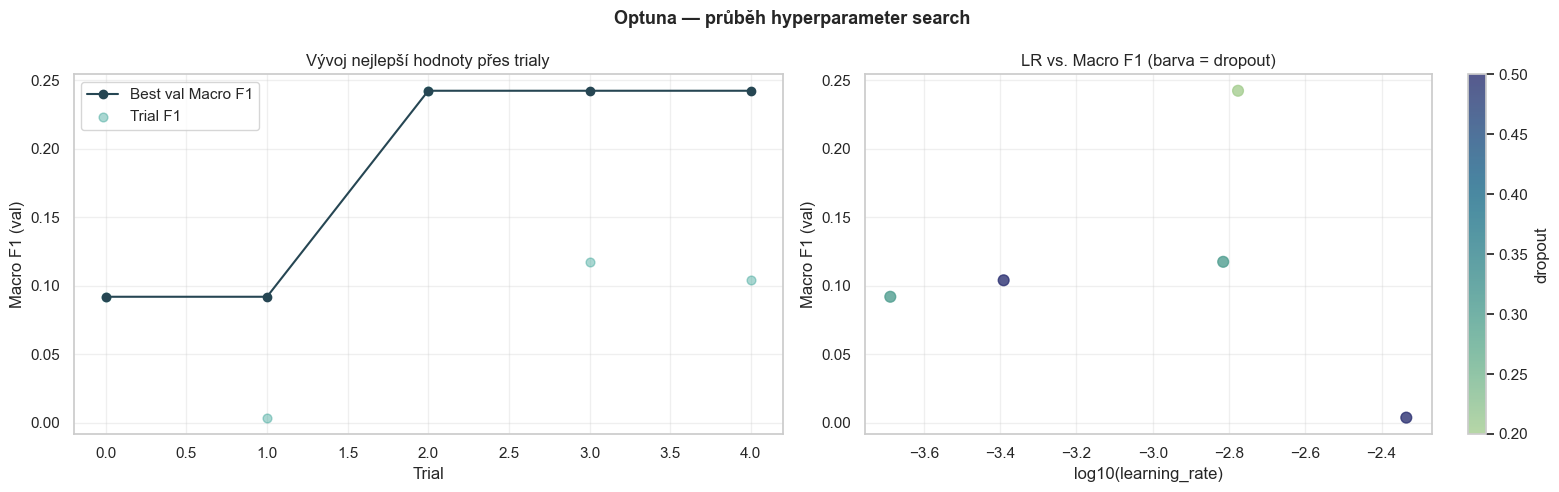

In [15]:
# Visualize the Optuna study
optuna_df = study.trials_dataframe()
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("Optuna — hyperparameter search progress", fontsize=13, fontweight="bold")

# Best value so far across trials
best_so_far = optuna_df["value"].cummax()
axes[0].plot(optuna_df.index, best_so_far, marker="o", color="#264653", label="Best val Macro F1")
axes[0].scatter(optuna_df.index, optuna_df["value"], alpha=0.4, color="#2a9d8f", s=40, label="Trial F1")
axes[0].set_xlabel("Trial")
axes[0].set_ylabel("Macro F1 (val)")
axes[0].set_title("Best value across trials")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Objective value vs. hyperparameters
param_cols = [c for c in optuna_df.columns if c.startswith("params_")]
if "params_learning_rate" in param_cols:
    sc = axes[1].scatter(
        np.log10(optuna_df["params_learning_rate"]),
        optuna_df["value"],
        c=optuna_df["params_dropout"],
        cmap="crest",
        s=60,
        alpha=0.8,
    )
    plt.colorbar(sc, ax=axes[1], label="dropout")
    axes[1].set_xlabel("log10(learning_rate)")
    axes[1].set_ylabel("Macro F1 (val)")
    axes[1].set_title("LR vs. Macro F1 (color = dropout)")
    axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("optuna_study.png", dpi=150, bbox_inches="tight")
plt.show()


#### 6.2.2 Training the Custom CNN with the Best Hyperparameters

In [17]:
BEST_PARAMS = study.best_params
print("Training Custom CNN with the Optuna hyperparameters:")
for k, v in BEST_PARAMS.items():
    print(f"  {k}: {v}")
print()

CUSTOM_EPOCHS = 40

# Build the dataloaders with the best batch_size
custom_train_ds, custom_val_ds, custom_test_ds = build_datasets(
    custom_train_transform, custom_val_transform
)
custom_train_loader, custom_val_loader, custom_test_loader = build_dataloaders(
    custom_train_ds, custom_val_ds, custom_test_ds,
    batch_size=BEST_PARAMS["batch_size"],
)

# Model
custom_model = CustomCNN(
    num_filters=BEST_PARAMS["num_filters"],
    dropout=BEST_PARAMS["dropout"],
).to(DEVICE)

criterion_custom = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer_custom = optim.Adam(custom_model.parameters(), lr=BEST_PARAMS["learning_rate"])
scheduler_custom = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_custom, mode="max", factor=0.5, patience=4, min_lr=1e-6
)

print(f"Number of model parameters: {sum(p.numel() for p in custom_model.parameters()):,}")
print(f"Training for {CUSTOM_EPOCHS} epochs...")
print()

history_custom, best_weights_custom = train_model(
    model=custom_model,
    train_loader=custom_train_loader,
    val_loader=custom_val_loader,
    criterion=criterion_custom,
    optimizer=optimizer_custom,
    scheduler=scheduler_custom,
    device=DEVICE,
    epochs=CUSTOM_EPOCHS
)


Training Custom CNN with the Optuna hyperparameters:
  num_filters: 32
  dropout: 0.2
  learning_rate: 0.0016738085788752138
  batch_size: 128

Number of model parameters: 295,591
Training for 40 epochs...

  Ep 01/40 | Train loss: 1.3519 acc: 0.1456 | Val loss: 2.8646 acc: 0.0138 | Val Macro F1: 0.0039 ← best
  Ep 02/40 | Train loss: 1.2910 acc: 0.1475 | Val loss: 2.6258 acc: 0.0172 | Val Macro F1: 0.0126 ← best
  Ep 03/40 | Train loss: 1.1781 acc: 0.2016 | Val loss: 2.0793 acc: 0.0902 | Val Macro F1: 0.0579 ← best
  Ep 04/40 | Train loss: 1.1405 acc: 0.2268 | Val loss: 2.1364 acc: 0.1082 | Val Macro F1: 0.0584 ← best
  Ep 05/40 | Train loss: 1.0670 acc: 0.2553 | Val loss: 1.9052 acc: 0.1372 | Val Macro F1: 0.1104 ← best
  Ep 06/40 | Train loss: 1.0032 acc: 0.2806 | Val loss: 1.9556 acc: 0.1693 | Val Macro F1: 0.1495 ← best
  Ep 07/40 | Train loss: 1.0153 acc: 0.2874 | Val loss: 1.9486 acc: 0.1506 | Val Macro F1: 0.1119
  Ep 08/40 | Train loss: 0.9814 acc: 0.2979 | Val loss: 1.9545 ac

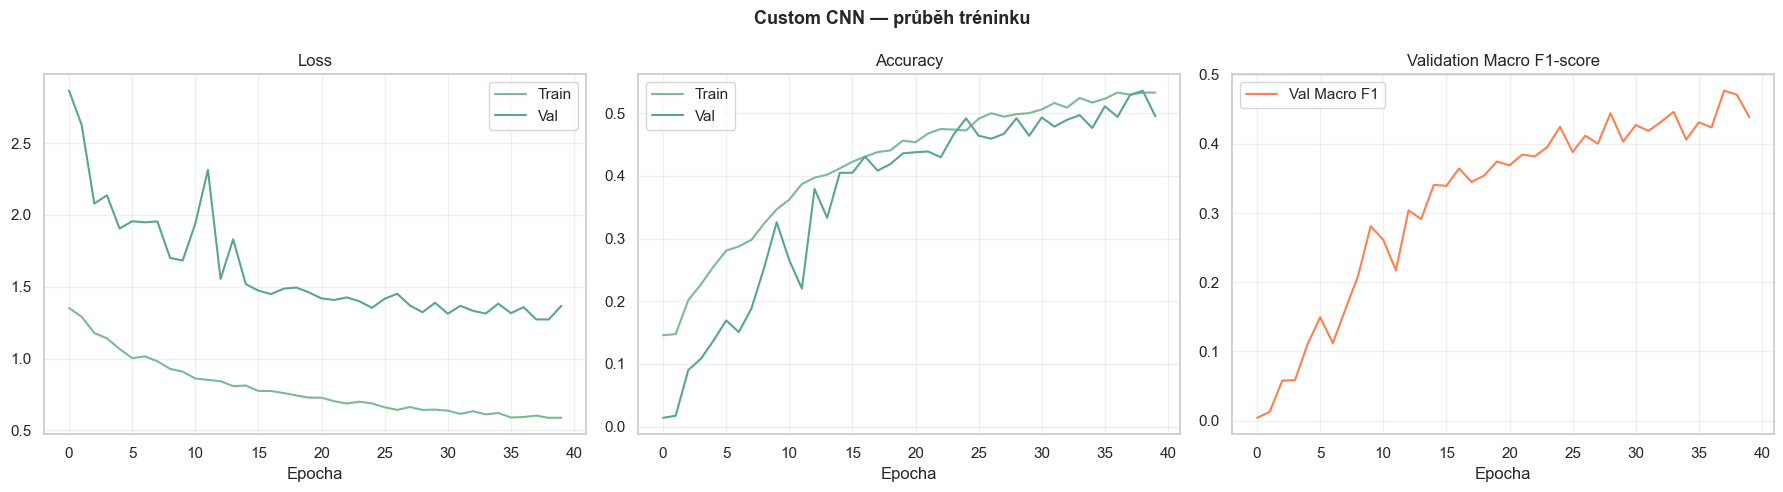


  Custom CNN (Optuna)
  Accuracy:             0.5300
  Macro Precision:      0.4725
  Macro Recall:         0.5547
  Macro F1-score:       0.4829  ⭐ (primary metric)
  Weighted F1-score:    0.5191

              precision    recall  f1-score   support

       angry       0.38      0.54      0.45       958
     disgust       0.25      0.78      0.37       111
        fear       0.29      0.13      0.18      1024
       happy       0.84      0.72      0.77      1774
     neutral       0.48      0.60      0.53      1233
         sad       0.44      0.31      0.36      1247
    surprise       0.64      0.80      0.71       831

    accuracy                           0.53      7178
   macro avg       0.47      0.55      0.48      7178
weighted avg       0.54      0.53      0.52      7178



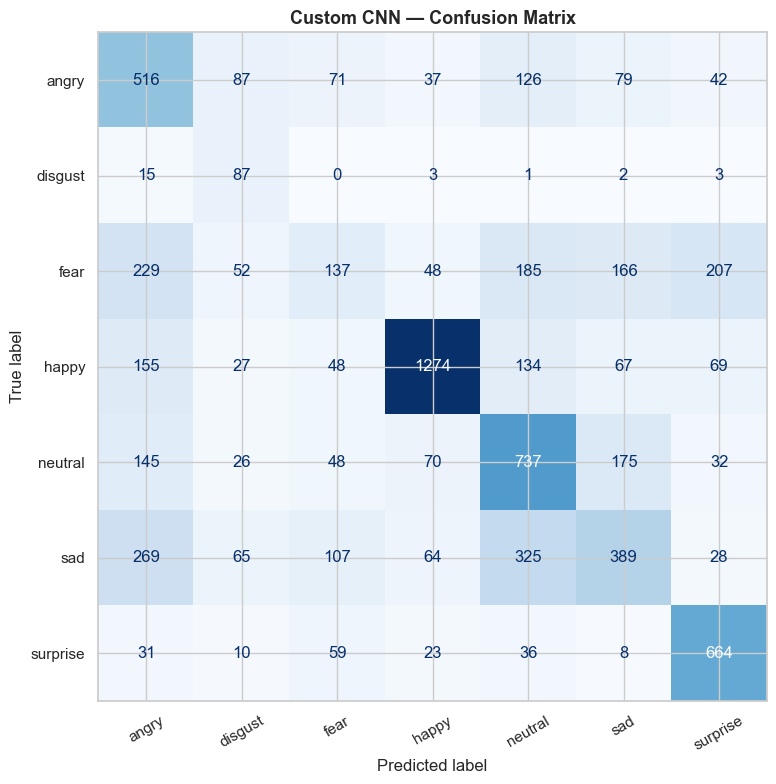

In [18]:
# Load the best weights and evaluate on the test set
custom_model.load_state_dict(best_weights_custom)

plot_history(history_custom, "Custom CNN — training history")

_, _, y_true_custom, y_pred_custom = evaluate(
    custom_model, custom_test_loader, criterion_custom, DEVICE
)
results_custom = compute_metrics(y_true_custom, y_pred_custom, "Custom CNN (Optuna)")
show_confusion_matrix(y_true_custom, y_pred_custom, "Custom CNN — Confusion Matrix")


### 6.3 Transfer Learning — ResNet18

The second model branch uses ResNet18 pretrained on ImageNet (1.2M images, 1,000 classes). Procedure:

1. Load the pretrained weights.
2. **Freeze** all layers except the last stage (`layer4` + `fc`).
3. Replace the `fc` output layer with a new classification head for 7 classes.
4. Fine-tune the entire network after an initial warm-up phase with the rest of the backbone frozen.


In [19]:
# --- Initialize the TL datasets (224×224, RGB) ---
tl_train_ds, tl_val_ds, tl_test_ds = build_datasets(tl_train_transform, tl_val_transform)
tl_train_loader, tl_val_loader, tl_test_loader = build_dataloaders(
    tl_train_ds, tl_val_ds, tl_test_ds, batch_size=64
)

print("TL dataset overview (224×224 RGB):")
print(f"  Train:      {len(tl_train_ds):,} images")
print(f"  Validation: {len(tl_val_ds):,} images")
print(f"  Test:       {len(tl_test_ds):,} images")


TL dataset overview (224×224 RGB):
  Train:      22,967 images
  Validation: 5,742 images
  Test:       7,178 images


In [20]:
def build_resnet18(num_classes: int = NUM_CLASSES, freeze_backbone: bool = True):
    """
    Build a ResNet18 with a replaced output head.

    Args:
        freeze_backbone: if True, freeze all layers except layer4 and fc.
    """
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

    if freeze_backbone:
        # Freeze everything
        for param in model.parameters():
            param.requires_grad = False
        # Unfreeze only layer4 and fc (feature head)
        for param in model.layer4.parameters():
            param.requires_grad = True

    # Replace the output layer
    in_features = model.fc.in_features
    model.fc = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(p=0.2),
        nn.Linear(256, num_classes),
    )
    return model


# --- Phase 1: Warm-up (frozen backbone) ---
print("=== Phase 1: Warm-up — training only the network head (layer4 + fc) ===")
TL_WARMUP_EPOCHS = 10
TL_FINETUNE_EPOCHS = 30

tl_model = build_resnet18(freeze_backbone=True).to(DEVICE)

trainable_params = sum(p.numel() for p in tl_model.parameters() if p.requires_grad)
total_params     = sum(p.numel() for p in tl_model.parameters())
print(f"Trainable parameters: {trainable_params:,} / {total_params:,} ({trainable_params/total_params:.1%})")

criterion_tl  = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer_tl  = optim.Adam(
    filter(lambda p: p.requires_grad, tl_model.parameters()), lr=1e-3
)
scheduler_tl  = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_tl, mode="max", factor=0.5, patience=3, min_lr=1e-6
)

history_warmup, best_weights_warmup = train_model(
    model=tl_model,
    train_loader=tl_train_loader,
    val_loader=tl_val_loader,
    criterion=criterion_tl,
    optimizer=optimizer_tl,
    scheduler=scheduler_tl,
    device=DEVICE,
    epochs=TL_WARMUP_EPOCHS
)
print("\n Warm-up phase finished.")


=== Phase 1: Warm-up — training only the network head (layer4 + fc) ===
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to ~/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:03<00:00, 15.1MB/s]


Trainable parameters: 8,526,855 / 11,309,639 (75.4%)
  Ep 01/10 | Train loss: 0.8627 acc: 0.4162 | Val loss: 1.3313 acc: 0.4760 | Val Macro F1: 0.4225 ← best
  Ep 02/10 | Train loss: 0.6609 acc: 0.5246 | Val loss: 1.3467 acc: 0.4777 | Val Macro F1: 0.4195
  Ep 03/10 | Train loss: 0.5848 acc: 0.5642 | Val loss: 1.2612 acc: 0.5350 | Val Macro F1: 0.4940 ← best
  Ep 04/10 | Train loss: 0.5533 acc: 0.5850 | Val loss: 1.1855 acc: 0.5620 | Val Macro F1: 0.5124 ← best
  Ep 05/10 | Train loss: 0.5280 acc: 0.6065 | Val loss: 1.1827 acc: 0.5895 | Val Macro F1: 0.5467 ← best
  Ep 06/10 | Train loss: 0.4827 acc: 0.6270 | Val loss: 1.2055 acc: 0.5773 | Val Macro F1: 0.5417
  Ep 07/10 | Train loss: 0.4888 acc: 0.6283 | Val loss: 1.1993 acc: 0.5751 | Val Macro F1: 0.5447
  Ep 08/10 | Train loss: 0.4577 acc: 0.6423 | Val loss: 1.1804 acc: 0.6008 | Val Macro F1: 0.5669 ← best
  Ep 09/10 | Train loss: 0.4483 acc: 0.6524 | Val loss: 1.1206 acc: 0.6026 | Val Macro F1: 0.5690 ← best
  Ep 10/10 | Train loss

In [21]:
# --- Phase 2: Fine-tuning (entire model unfrozen) ---
print("=== Phase 2: Fine-tuning — unfreezing the entire ResNet18 ===")

# Load the best weights from the warm-up phase
tl_model.load_state_dict(best_weights_warmup)

# Unfreeze all layers
for param in tl_model.parameters():
    param.requires_grad = True

trainable_params = sum(p.numel() for p in tl_model.parameters() if p.requires_grad)
print(f"Trainable parameters after unfreezing: {trainable_params:,}")

# Use lower, layer-wise learning rates for fine-tuning (to avoid overwriting pretrained weights)
optimizer_ft = optim.AdamW([
    {"params": tl_model.layer1.parameters(), "lr": 1e-5},
    {"params": tl_model.layer2.parameters(), "lr": 1e-5},
    {"params": tl_model.layer3.parameters(), "lr": 2e-5},
    {"params": tl_model.layer4.parameters(), "lr": 5e-5},
    {"params": tl_model.fc.parameters(),     "lr": 1e-4},
], weight_decay=1e-4)

scheduler_ft = optim.lr_scheduler.CosineAnnealingLR(optimizer_ft, T_max=TL_FINETUNE_EPOCHS, eta_min=1e-7)

history_finetune, best_weights_finetune = train_model(
    model=tl_model,
    train_loader=tl_train_loader,
    val_loader=tl_val_loader,
    criterion=criterion_tl,
    optimizer=optimizer_ft,
    scheduler=scheduler_ft,
    device=DEVICE,
    epochs=TL_FINETUNE_EPOCHS
)
print("\n Fine-tuning finished.")


=== Phase 2: Fine-tuning — unfreezing the entire ResNet18 ===
Trainable parameters after unfreezing: 11,309,639
  Ep 01/30 | Train loss: 0.3968 acc: 0.6805 | Val loss: 1.1853 acc: 0.6228 | Val Macro F1: 0.5996 ← best
  Ep 02/30 | Train loss: 0.3707 acc: 0.6988 | Val loss: 1.2199 acc: 0.6271 | Val Macro F1: 0.6095 ← best
  Ep 03/30 | Train loss: 0.3632 acc: 0.7024 | Val loss: 1.1813 acc: 0.6294 | Val Macro F1: 0.6039
  Ep 04/30 | Train loss: 0.3513 acc: 0.7135 | Val loss: 1.2294 acc: 0.6398 | Val Macro F1: 0.6216 ← best
  Ep 05/30 | Train loss: 0.3481 acc: 0.7158 | Val loss: 1.2013 acc: 0.6379 | Val Macro F1: 0.6129
  Ep 06/30 | Train loss: 0.3306 acc: 0.7253 | Val loss: 1.2242 acc: 0.6423 | Val Macro F1: 0.6215
  Ep 07/30 | Train loss: 0.3270 acc: 0.7290 | Val loss: 1.2699 acc: 0.6400 | Val Macro F1: 0.6286 ← best
  Ep 08/30 | Train loss: 0.3214 acc: 0.7328 | Val loss: 1.3106 acc: 0.6454 | Val Macro F1: 0.6308 ← best
  Ep 09/30 | Train loss: 0.3232 acc: 0.7391 | Val loss: 1.3467 acc: 0

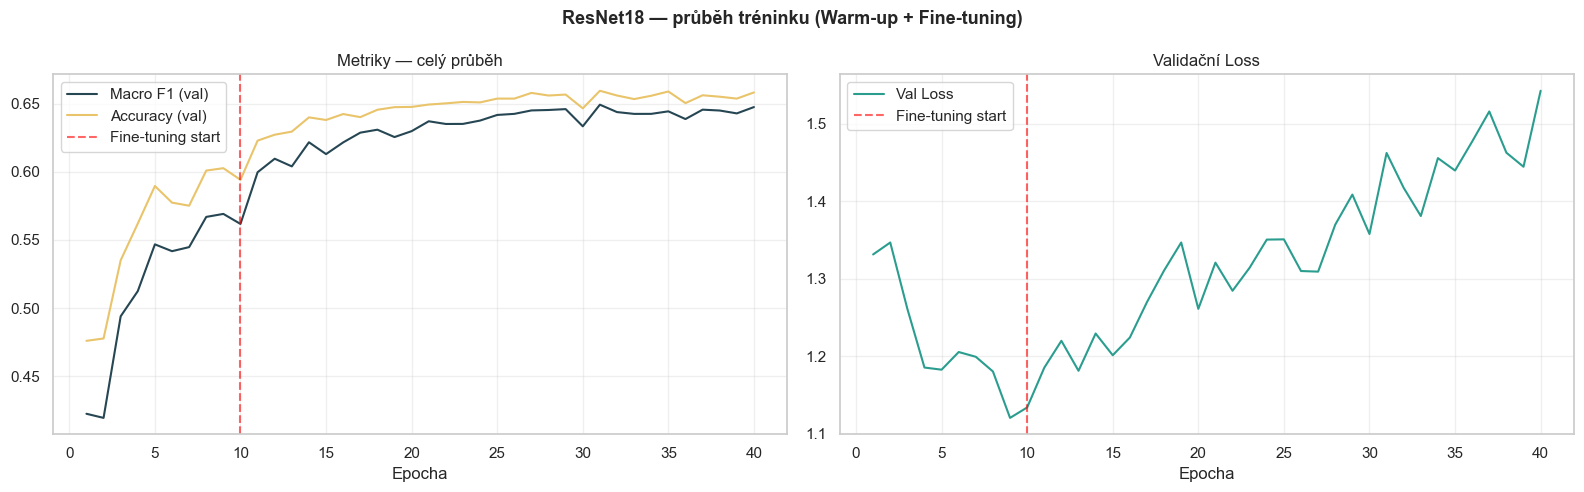


  ResNet18 Transfer Learning
  Accuracy:             0.6566
  Macro Precision:      0.6663
  Macro Recall:         0.6402
  Macro F1-score:       0.6491  ⭐ (primary metric)
  Weighted F1-score:    0.6575

              precision    recall  f1-score   support

       angry       0.55      0.64      0.59       958
     disgust       0.83      0.60      0.70       111
        fear       0.52      0.45      0.48      1024
       happy       0.90      0.82      0.86      1774
     neutral       0.59      0.67      0.62      1233
         sad       0.54      0.52      0.53      1247
    surprise       0.74      0.79      0.77       831

    accuracy                           0.66      7178
   macro avg       0.67      0.64      0.65      7178
weighted avg       0.66      0.66      0.66      7178



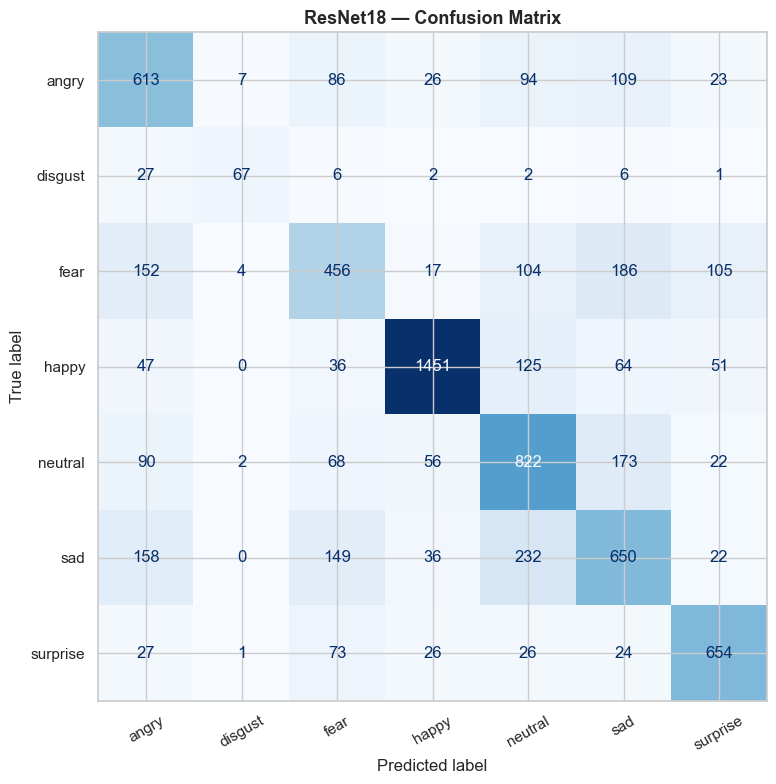

In [22]:
# Load the best weights and evaluate
tl_model.load_state_dict(best_weights_finetune)

# Plot both TL phases
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle("ResNet18 — training history (warm-up + fine-tuning)", fontsize=13, fontweight="bold")

for key, label, color in [
    ("val_f1_macro", "Macro F1 (val)", "#264653"),
    ("val_acc",      "Accuracy (val)", "#e9c46a"),
]:
    combined = history_warmup[key] + history_finetune[key]
    ep = list(range(1, len(combined) + 1))
    warmup_end = len(history_warmup[key])
    axes[0].plot(ep, combined, label=label, color=color)
axes[0].axvline(x=warmup_end, color="red", linestyle="--", alpha=0.6, label="Fine-tuning start")
axes[0].set_title("Metrics — full run")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

combined_loss = history_warmup["val_loss"] + history_finetune["val_loss"]
axes[1].plot(range(1, len(combined_loss) + 1), combined_loss, color="#2a9d8f", label="Val Loss")
axes[1].axvline(x=len(history_warmup["val_loss"]), color="red", linestyle="--", alpha=0.6, label="Fine-tuning start")
axes[1].set_title("Validation loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("history_ResNet18.png", dpi=150, bbox_inches="tight")
plt.show()

_, _, y_true_tl, y_pred_tl = evaluate(tl_model, tl_test_loader, criterion_tl, DEVICE)
results_tl = compute_metrics(y_true_tl, y_pred_tl, "ResNet18 Transfer Learning")
show_confusion_matrix(y_true_tl, y_pred_tl, "ResNet18 — Confusion Matrix")


## 7. Model Comparison

In [23]:
# Final comparison table
comparison_data = [
    {k: v for k, v in results_custom.items() if k != "y_pred"},
    {k: v for k, v in results_tl.items()     if k != "y_pred"},
]
comparison_df = pd.DataFrame(comparison_data).set_index("model")
metric_cols = ["accuracy", "prec_macro", "rec_macro", "f1_macro", "f1_weighted"]

print("\n=== FINAL MODEL COMPARISON ===")
display(
    comparison_df[metric_cols].style
    .format("{:.4f}")
    .highlight_max(axis=0, color="#d4edda")  # green = best value in each column
    .set_caption("Custom CNN vs. transfer learning model on the test set")
)



=== FINAL MODEL COMPARISON ===


,accuracy,prec_macro,rec_macro,f1_macro,f1_weighted
model,,,,,
Custom CNN (Optuna),0.5300,0.4725,0.5547,0.4829,0.5191
ResNet18 Transfer Learning,0.6566,0.6663,0.6402,0.6491,0.6575


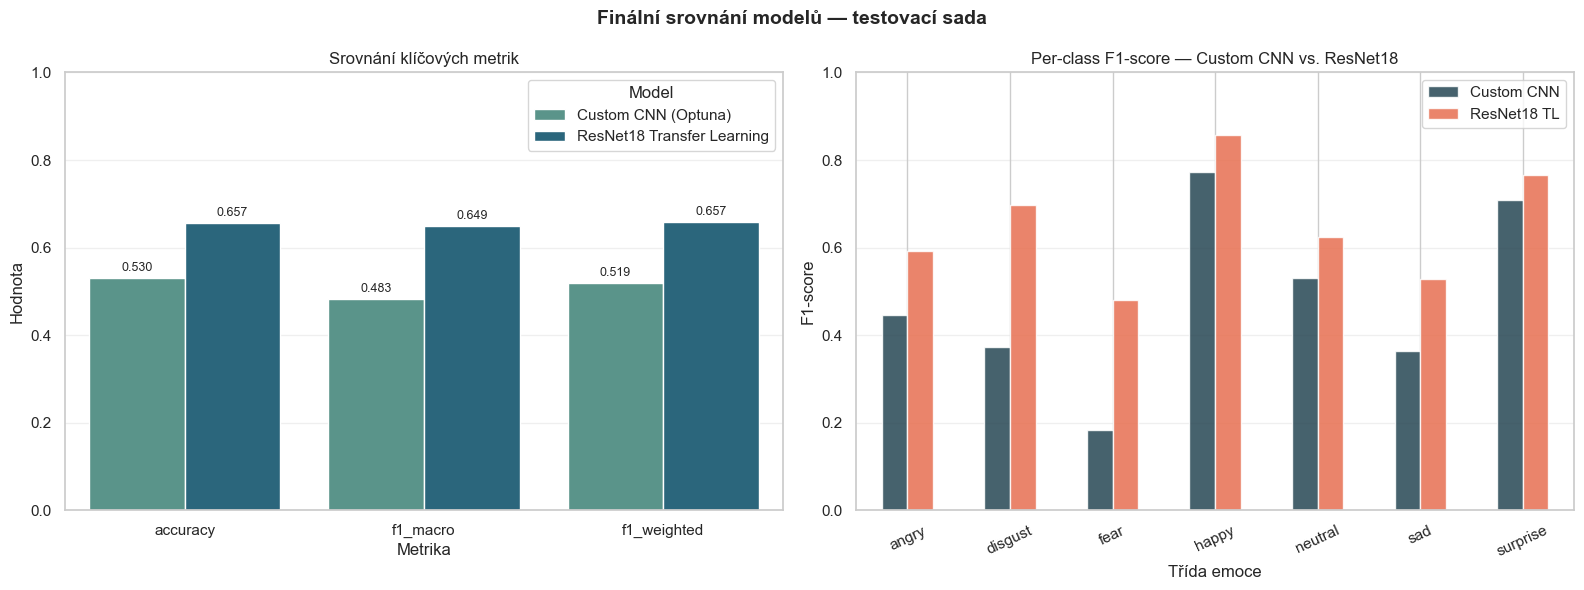

In [24]:
# Comparison plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Final model comparison — test set", fontsize=14, fontweight="bold")

metrics_to_plot = ["accuracy", "f1_macro", "f1_weighted"]
plot_df = comparison_df[metrics_to_plot].reset_index().melt(
    id_vars="model", var_name="Metric", value_name="Value"
)

colors = {"accuracy": "#264653", "f1_macro": "#2a9d8f", "f1_weighted": "#e9c46a"}

sns.barplot(data=plot_df, x="Metric", y="Value", hue="model", ax=axes[0], palette="crest")
axes[0].set_title("Key metrics")
axes[0].set_ylim(0, 1)
axes[0].legend(title="Model")
axes[0].grid(axis="y", alpha=0.3)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.3f", padding=3, fontsize=9)

# Per-class F1 comparison
cr_custom = classification_report(y_true_custom, y_pred_custom, target_names=CLASSES,
                                   output_dict=True, zero_division=0)
cr_tl     = classification_report(y_true_tl,     y_pred_tl,     target_names=CLASSES,
                                   output_dict=True, zero_division=0)

per_class_df = pd.DataFrame({
    "Custom CNN":    [cr_custom[c]["f1-score"] for c in CLASSES],
    "ResNet18 TL":   [cr_tl[c]["f1-score"]     for c in CLASSES],
}, index=CLASSES)

per_class_df.plot(kind="bar", ax=axes[1], color=["#264653", "#e76f51"], alpha=0.85, edgecolor="white")
axes[1].set_title("Per-class F1-score — Custom CNN vs. ResNet18")
axes[1].set_xlabel("Emotion class")
axes[1].set_ylabel("F1-score")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()


## 8. Deployment Pipeline

### 8.1 Export to ONNX

ONNX (Open Neural Network Exchange) makes it possible to deploy a model independently of the training framework — the model can then run from C++, Java, or on dedicated inference runtimes (ONNX Runtime, TensorRT, OpenVINO).


In [60]:
models_to_export = {
    "Custom_CNN": {
        "model": custom_model,
        "input_size": (1, 1, CUSTOM_SIZE, CUSTOM_SIZE)
    },
    "ResNet18": {
        "model": tl_model,
        "input_size": (1, 3, IMG_SIZE, IMG_SIZE)
    }
}

print("-" * 50)
print("Exporting all models to ONNX...")


for model_key, info in models_to_export.items():
    model = info["model"]
    input_size = info["input_size"]
    
    onnx_path = Path(f"fer2013_{model_key}.onnx")
    
    model.eval()
    dummy_input = torch.zeros(*input_size).to(DEVICE)
    
    # Export with dynamo disabled (legacy TorchScript exporter, for compatibility with recent PyTorch)
    torch.onnx.export(
        model,
        dummy_input,
        str(onnx_path),
        export_params=True,
        opset_version=17,
        do_constant_folding=True,
        input_names=["input"],
        output_names=["logits"],
        dynamic_axes={"input": {0: "batch_size"}, "logits": {0: "batch_size"}},
        dynamo=False
    )
    
    # Validate and report
    onnx_model = onnx.load(str(onnx_path))
    onnx.checker.check_model(onnx_model)
    file_size_mb = onnx_path.stat().st_size / (1024 * 1024)
    print(f"{model_key:10} | {file_size_mb:>5.2f} MB | Opset: {onnx_model.opset_import[0].version}")

--------------------------------------------------
Exporting all models to ONNX...
Custom_CNN |  1.13 MB | Opset: 17
ResNet18   | 43.13 MB | Opset: 17


### 8.2 Inference Class

In [5]:
class FERInference:
    """
    Inference class for facial emotion recognition.

    Usage:
        predictor = FERInference("fer2013_XXXX.onnx", is_transfer_learning=True)
        emotion, probs = predictor.predict("path/to/image.png")
        print(emotion)  # e.g. "happy"

    Attributes:
        model_path (str | Path): Path to the ONNX file.
        is_transfer_learning (bool): True → 224×224 RGB input, False → 48×48 grayscale input.
    """

    CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

    # Normalization statistics
    _TL_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    _TL_STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __init__(self, model_path: str | Path, is_transfer_learning: bool = True):
        self.model_path          = Path(model_path)
        self.is_transfer_learning = is_transfer_learning
        self._session            = None
        self._load_model()

    def _load_model(self) -> None:
        """Load the ONNX model into an ONNX Runtime inference session."""
        if not self.model_path.exists():
            raise FileNotFoundError(f"ONNX model not found: {self.model_path}")

        providers = ["CUDAExecutionProvider", "CPUExecutionProvider"]
        self._session = ort.InferenceSession(str(self.model_path), providers=providers)
        self._input_name  = self._session.get_inputs()[0].name
        self._output_name = self._session.get_outputs()[0].name

        used_provider = self._session.get_providers()[0]
        print(f" ONNX model loaded: {self.model_path.name}")
        print(f"   Inference provider: {used_provider}")

    def _preprocess(self, image: Image.Image) -> np.ndarray:
        """
        Preprocess a raw PIL image.

        1. Convert to grayscale (L channel)
        2. Resize to the target resolution
        3. Convert to float32 and normalize
        4. Add the batch dimension: (H, W) → (1, C, H, W)
        """
        if self.is_transfer_learning:
            # 48×48 grayscale → 224×224 RGB
            img = image.convert("L").resize((224, 224), Image.BILINEAR)
            arr = np.array(img, dtype=np.float32) / 255.0        # (224, 224)
            arr = np.stack([arr, arr, arr], axis=0)               # (3, 224, 224)
            arr = (arr - self._TL_MEAN[:, None, None]) / self._TL_STD[:, None, None]
        else:
            # 48×48 grayscale
            img = image.convert("L").resize((48, 48), Image.BILINEAR)
            arr = np.array(img, dtype=np.float32) / 255.0         # (48, 48)
            arr = (arr - 0.5) / 0.5                                # normalize
            arr = arr[np.newaxis, :, :]                            # (1, 48, 48)

        return arr[np.newaxis, :, :, :].astype(np.float32)        # (1, C, H, W)

    def predict(self, image_input: str | Path | Image.Image) -> tuple[str, dict]:
        """
        Run inference on an input image.

        Args:
            image_input: Path to an image (str/Path) or a PIL Image object.

        Returns:
            tuple: (predicted class as str, dict {class: probability})
        """
        # Load the image
        if isinstance(image_input, (str, Path)):
            image = Image.open(image_input)
        elif isinstance(image_input, Image.Image):
            image = image_input
        else:
            raise TypeError(f"Unsupported input type: {type(image_input)}")

        # Preprocessing
        input_tensor = self._preprocess(image)

        # Inference
        outputs = self._session.run(
            [self._output_name],
            {self._input_name: input_tensor},
        )
        logits = outputs[0][0]  # (num_classes,)

        # Softmax → probabilities
        exp_logits  = np.exp(logits - logits.max())
        probs       = exp_logits / exp_logits.sum()
        pred_idx    = int(np.argmax(probs))
        pred_class  = self.CLASSES[pred_idx]

        prob_dict = {cls: round(float(p), 4) for cls, p in zip(self.CLASSES, probs)}
        return pred_class, prob_dict

    def predict_batch(self, image_paths: list) -> list[tuple[str, dict]]:
        """Convenience method for running inference on multiple images."""
        return [self.predict(p) for p in image_paths]


### 8.3 Inference Class Demo

In [63]:
# Initialize the inference engines
predictor_cnn = FERInference(
    model_path="fer2013_Custom_CNN.onnx",
    is_transfer_learning=False  # Custom CNN uses 1 channel (48x48)
)

predictor_resnet = FERInference(
    model_path="fer2013_ResNet18.onnx",
    is_transfer_learning=True   # ResNet uses 3 channels (transfer learning)
)

print("\n=== Demo predictions on sample test images (model comparison) ===\n")

demo_results = []
for cls in CLASSES:
    cls_dir   = TEST_DIR / cls
    img_paths = list(cls_dir.glob("*.png")) + list(cls_dir.glob("*.jpg"))
    if not img_paths:
        continue
    sample_path = random.choice(img_paths[:20])  # randomly pick one image for this class

    # 1. Custom CNN prediction
    pred_cnn, probs_cnn = predictor_cnn.predict(sample_path)
    correct_cnn = "✅" if pred_cnn == cls else "❌"

    # 2. ResNet18 prediction
    pred_resnet, probs_resnet = predictor_resnet.predict(sample_path)
    correct_resnet = "✅" if pred_resnet == cls else "❌"

    # Collect the results for the table
    demo_results.append({
        "True class": cls,
        "CNN: Prediction": pred_cnn,
        "CNN: Confidence": f"{probs_cnn[pred_cnn]:.2%}",
        "CNN: Result": correct_cnn,
        "ResNet: Prediction": pred_resnet,
        "ResNet: Confidence": f"{probs_resnet[pred_resnet]:.2%}",
        "ResNet: Result": correct_resnet,
    })

# Display the results as a pandas table
demo_df = pd.DataFrame(demo_results)
print("\nDetailed results:")
display(demo_df)


 ONNX model loaded: fer2013_Custom_CNN.onnx
   Inference provider: CPUExecutionProvider
 ONNX model loaded: fer2013_ResNet18.onnx
   Inference provider: CPUExecutionProvider

=== Demo predictions on sample test images (model comparison) ===


Detailed results:


,True class,CNN: Prediction,CNN: Confidence,CNN: Result,ResNet: Prediction,ResNet: Confidence,ResNet: Result
0,angry,angry,32.60%,✅,sad,34.26%,❌
1,disgust,disgust,46.89%,✅,fear,43.40%,❌
2,fear,neutral,59.49%,❌,neutral,57.26%,❌
3,happy,happy,39.79%,✅,happy,98.13%,✅
4,neutral,surprise,30.11%,❌,neutral,51.75%,✅
5,sad,happy,43.49%,❌,sad,98.11%,✅
6,surprise,surprise,58.97%,✅,surprise,95.84%,✅


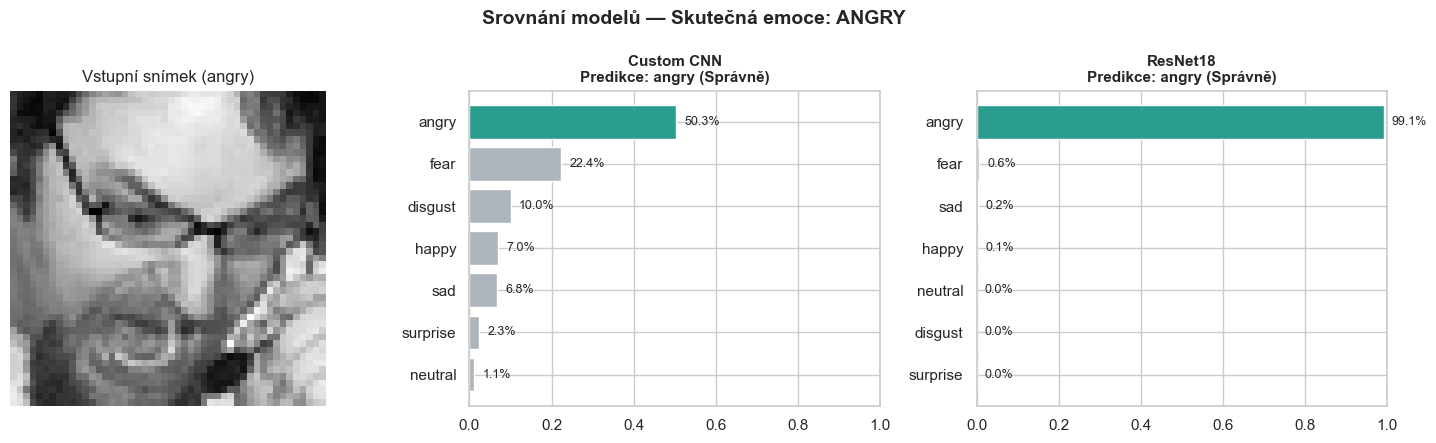

--------------------------------------------------------------------------------


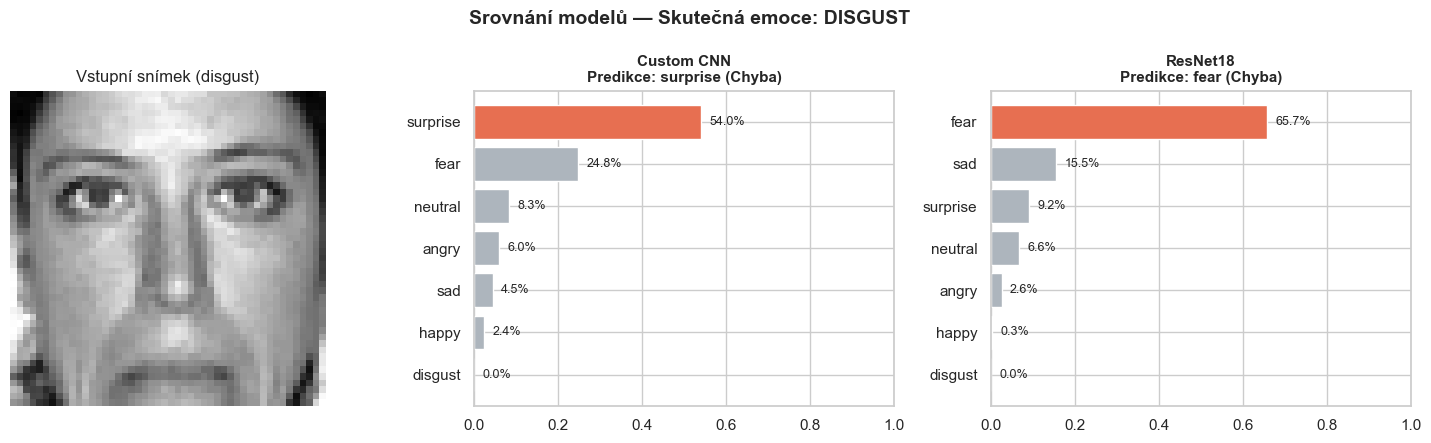

--------------------------------------------------------------------------------


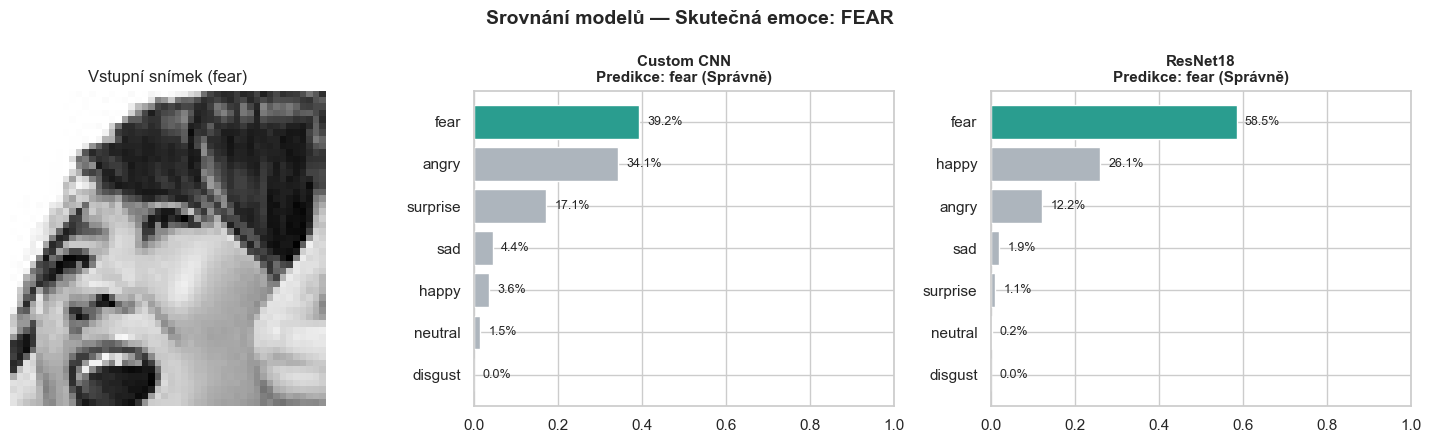

--------------------------------------------------------------------------------


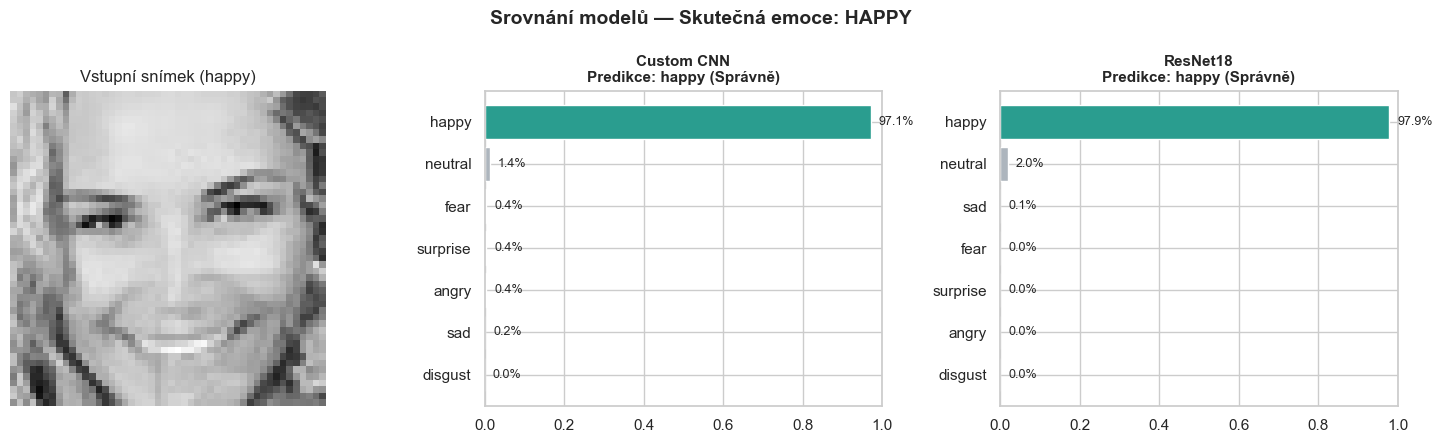

--------------------------------------------------------------------------------


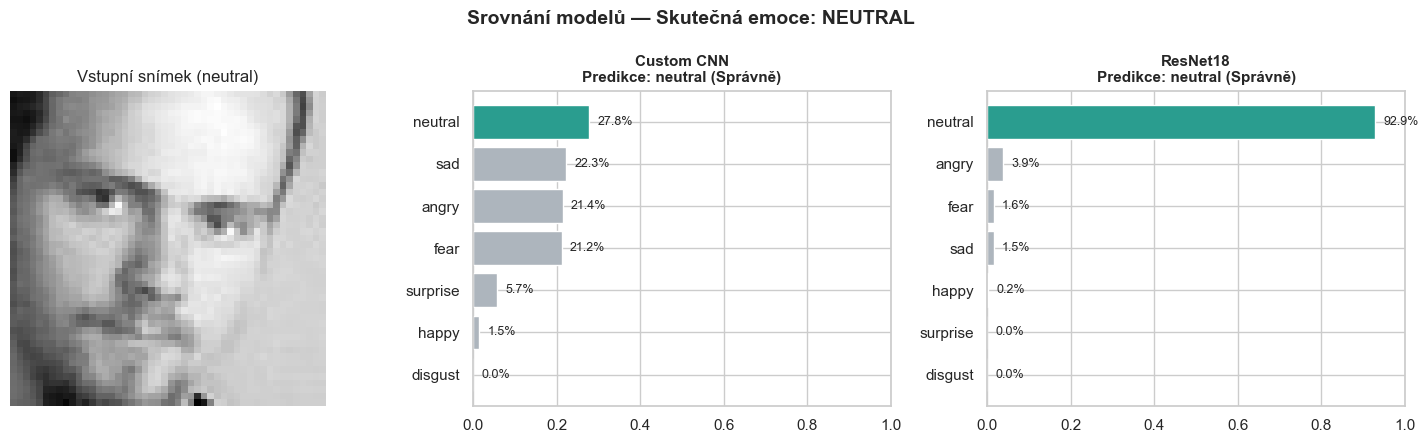

--------------------------------------------------------------------------------


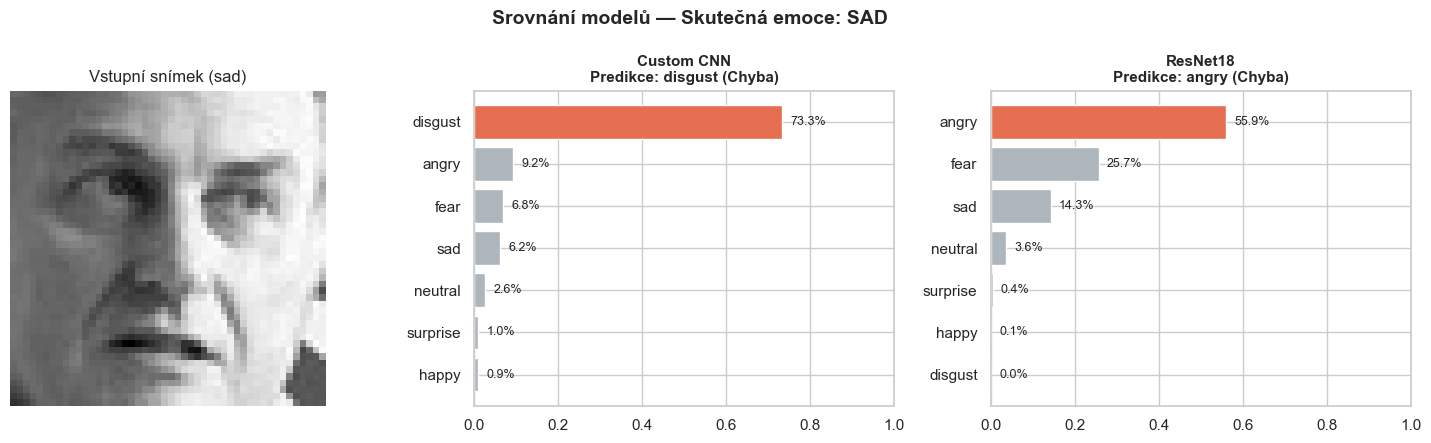

--------------------------------------------------------------------------------


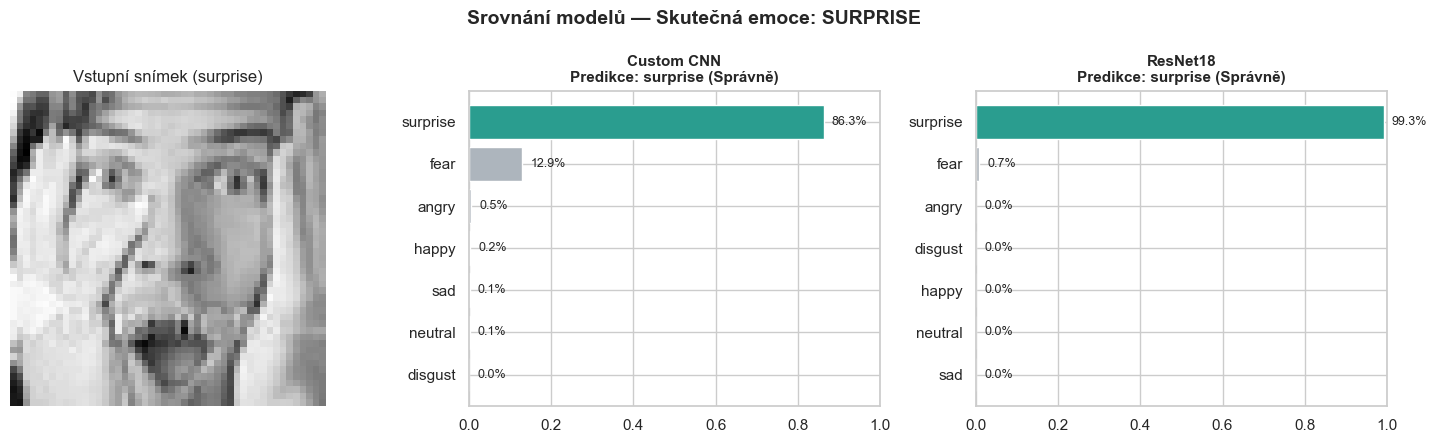

--------------------------------------------------------------------------------


In [64]:
for test_cls in CLASSES:
    
    # 1. Load the first available image for this emotion
    cls_dir = TEST_DIR / test_cls
    sample_imgs = list(cls_dir.glob("*.png")) + list(cls_dir.glob("*.jpg"))

    if not sample_imgs:
        print(f"⚠️ No images found for class '{test_cls}'. Skipping.")
        continue

    sample_path = sample_imgs[0]

    # 2. Get predictions from BOTH models
    pred_cnn, probs_cnn = predictor_cnn.predict(sample_path)
    pred_resnet, probs_resnet = predictor_resnet.predict(sample_path)

    # 3. Set up the figure (3 subplots side by side)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    fig.suptitle(f"Model comparison — true emotion: {test_cls.upper()}", fontsize=14, fontweight="bold")

    # --- Subplot 1: original image ---
    img_display = Image.open(sample_path).convert("L")
    axes[0].imshow(img_display, cmap="gray")
    axes[0].axis("off")
    axes[0].set_title(f"Input image ({test_cls})", fontsize=12)

    # --- Helper function for the bar chart ---
    def plot_probs(ax, probs_dict, predicted_class, model_name):
        # Sort by probability, descending
        sorted_probs = dict(sorted(probs_dict.items(), key=lambda x: -x[1]))

        # Colors: green for a correct prediction, red for a wrong one
        is_correct = predicted_class == test_cls
        main_color = "#2a9d8f" if is_correct else "#e76f51"
        colors_bar = [main_color if k == predicted_class else "#adb5bd" for k in sorted_probs]

        # Horizontal bars
        ax.barh(list(sorted_probs.keys()), list(sorted_probs.values()), color=colors_bar)

        # Styling and labels
        status = "Correct" if is_correct else "Wrong"
        ax.set_title(f"{model_name}\nPrediction: {predicted_class} ({status})", fontsize=11, fontweight="bold")
        ax.set_xlim(0, 1)
        ax.invert_yaxis()  # highest probability on top

        # Percentage labels next to the bars
        for i, (k, v) in enumerate(sorted_probs.items()):
            ax.text(v + 0.02, i, f"{v:.1%}", va="center", fontsize=9)

    # --- Subplots 2 and 3: bar charts via the helper ---
    plot_probs(axes[1], probs_cnn, pred_cnn, "Custom CNN")
    plot_probs(axes[2], probs_resnet, pred_resnet, "ResNet18")

    plt.tight_layout()

    # 4. Save with a per-emotion file name (e.g. inference_demo_happy.png)
    save_name = f"inference_demo_{test_cls}.png"
    plt.savefig(save_name, dpi=150, bbox_inches="tight")

    # Show the figure in the notebook
    plt.show()
    print("-" * 80) # visual separator between emotions


### 8.4 Demo on Custom Photos

This cell runs both ONNX models on arbitrary photos: an OpenCV Haar cascade detects and crops the largest face, and `FERInference` handles the rest of the preprocessing.

> **Note:** the `My_imgs/` folder is **not included** in this repository, and the outputs of the cell below were removed for privacy (it was originally run on the author's personal photos). To try it, create a `My_imgs/` folder next to the notebook, put your own `.png` / `.jpg` / `.jpeg` photos in it and run the cell.

In [ ]:
import cv2

IMAGE_DIR = r"My_imgs"   # >>> FOLDER WITH YOUR OWN PHOTOS (not included in the repo) <<<
CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]

predictor_cnn = FERInference(
    model_path="fer2013_Custom_CNN.onnx",
    is_transfer_learning=False  # Custom CNN uses 1 channel (48x48)
)

predictor_resnet = FERInference(
    model_path="fer2013_ResNet18.onnx",
    is_transfer_learning=True   # ResNet uses 3 channels (transfer learning)
)

# Haar cascade face detector (created once for all images)
_FACE_CASCADE = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Find all images in the folder (png, jpg, jpeg)
EXTS = ("*.png", "*.jpg", "*.jpeg")
image_paths = sorted(p for ext in EXTS for p in Path(IMAGE_DIR).glob(ext))
print(f"Found {len(image_paths)} images in folder '{IMAGE_DIR}'\n")

for IMAGE_PATH in image_paths:
    # --- 1. Face detection and cropping (Haar cascade) ---
    orig_pil = Image.open(IMAGE_PATH).convert("RGB")
    gray = np.array(orig_pil.convert("L"))
    faces = _FACE_CASCADE.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(40, 40))

    if len(faces) > 0:
        x, y, w, h = max(faces, key=lambda r: r[2] * r[3])  # largest face
        mx, my = int(w * 0.25), int(h * 0.25)               # margin around the face
        W, H = orig_pil.size
        face_pil = orig_pil.crop((max(0, x - mx), max(0, y - my),
                                  min(W, x + w + mx), min(H, y + h + my)))
        found = True
    else:
        face_pil, found = orig_pil, False  # fallback: whole image

    # --- 2. Predict with BOTH models (FERInference handles preprocessing) ---
    pred_cnn,    probs_cnn    = predictor_cnn.predict(face_pil)
    pred_resnet, probs_resnet = predictor_resnet.predict(face_pil)

    # --- 3. Visualization: photo + face crop + two bar charts ---
    fig = plt.figure(figsize=(16, 4))
    fig.suptitle(f"Custom photo: {Path(IMAGE_PATH).name}", fontsize=13, fontweight="bold")

    ax1 = fig.add_subplot(1, 4, 1)
    ax1.imshow(orig_pil); ax1.set_title("Input photo"); ax1.axis("off")

    ax2 = fig.add_subplot(1, 4, 2)
    ax2.imshow(face_pil.convert("L"), cmap="gray")
    ax2.set_title("Detected face" if found else "Face NOT FOUND\n(whole image)")
    ax2.axis("off")

    for ax, title, pred, probs in [
        (fig.add_subplot(1, 4, 3), f"Custom CNN → {pred_cnn} ({probs_cnn[pred_cnn]:.1%})", pred_cnn, probs_cnn),
        (fig.add_subplot(1, 4, 4), f"ResNet18 → {pred_resnet} ({probs_resnet[pred_resnet]:.1%})", pred_resnet, probs_resnet),
    ]:
        classes = list(probs.keys())
        values  = [probs[c] for c in classes]
        colors  = ["#e74c3c" if c == pred else "#5dade2" for c in classes]
        bars = ax.barh(classes, values, color=colors)
        ax.set_xlim(0, 1); ax.set_title(title, fontsize=10); ax.invert_yaxis()
        for bar, v in zip(bars, values):
            ax.text(min(v + 0.02, 0.9), bar.get_y() + bar.get_height() / 2, f"{v:.1%}", va="center", fontsize=8)

    plt.tight_layout(); plt.show()

    print(f"[{Path(IMAGE_PATH).name}]")
    print(f"  Custom CNN: {pred_cnn:10s} ({probs_cnn[pred_cnn]:.1%})")
    print(f"  ResNet18:   {pred_resnet:10s} ({probs_resnet[pred_resnet]:.1%})")
    if not found:
        print("  ⚠️  No face detected — the prediction may be unreliable.")
    print()

## 9. Summary

### What worked

- **Transfer learning (ResNet18)** clearly outperformed the custom CNN on all key metrics. The pretrained ImageNet features transferred despite the domain shift (natural photos → faces), even though the input was grayscale replicated into 3 channels.
- **Two-stage training (warm-up + fine-tuning)** paid off: a short warm-up trained the network head without the risk of "overwriting" the pretrained weights with a large learning rate, and fine-tuning with layer-wise learning rates then gradually adapted the whole network.
- **WeightedRandomSampler + class_weight** counteracted the bias toward majority classes — even the rarest class, `disgust` (~440 training images), reached a test recall of 0.78 with the custom CNN and an F1 of 0.70 with ResNet18.
- **Optuna** systematically searched the custom CNN's hyperparameter space (number of filters, dropout, learning rate, batch size) using a TPE sampler, with a MedianPruner configured to stop weak trials early.
- **Augmentation** (horizontal flip, mild rotation, ColorJitter) served as the main regularizer against overfitting in the custom CNN, alongside dropout and weight decay.

### What didn't work / room for improvement

- Even after Optuna tuning, the **custom CNN** reaches a clearly lower Macro F1 than ResNet18. A 3× ConvBlock architecture on 48×48 images has limited capacity — especially for visually similar classes such as `fear`, `sad` and `neutral`.
- **The `disgust` class** has very few training samples (~440 images), and the two models handle it very differently. The custom CNN reaches high recall (0.78) but low precision (0.25), for an F1 of only 0.37 — it over-predicts `disgust`, likely because of the large class weight (9.19). ResNet18 is far more balanced (precision 0.83, recall 0.60, F1 0.70). More minority-class data could help further: synthetic oversampling (SMOTE-style methods for images) or GAN-based augmentation.
- **Custom CNN overfitting**: the gap between training and validation loss grew in later epochs, although dropout and augmentation slowed it down. Stronger regularization (label smoothing, MixUp) could help.
- **Confusion between neighboring emotions** (`fear`↔`sad`, `neutral`↔`sad`) is visible in the confusion matrices of both models — an inherent problem of FER-2013, where the boundaries between emotions are subjective even for human annotators.

### Possible next steps

- Try a stronger backbone (EfficientNet-B2, ViT-B/16) for potentially better feature extraction.
- Add **label smoothing** to the loss for better confidence calibration.
- Add mini-batch-level **MixUp** or **CutMix** augmentation.
- Explore **ordinal regression** for classes that have a natural ordering by emotion intensity.
- For `disgust`, try **GAN-based data augmentation** or add an external dataset (AffectNet, RAF-DB).
